In [1]:
pip install numpy pandas matplotlib seaborn scikit-learn

Original Dataset Shape: (70000, 784)
Dataset Shape: (5000, 784)
Reduced Shape: (5000, 148)
Reconstructed Shape: (5000, 784)


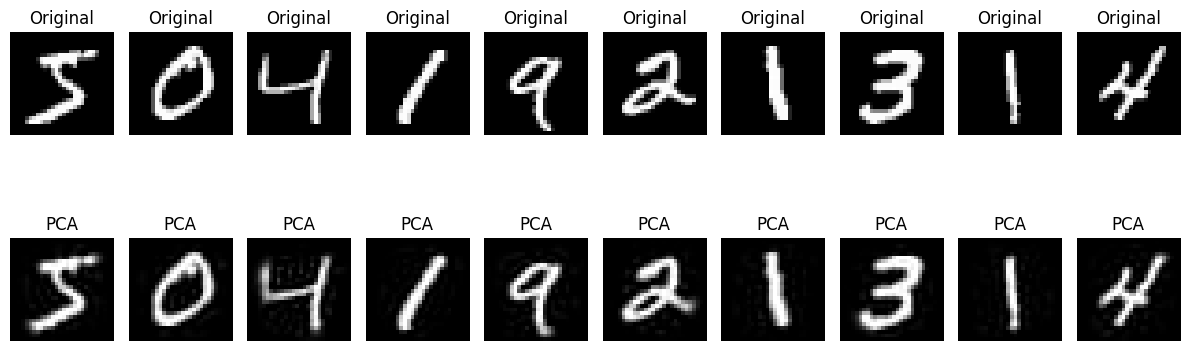

Original Features:  784
Compressed Image Size:  740000
Number of Principal Components: 0.95


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

mnist = fetch_openml('mnist_784', version=1, as_frame=False)


X = mnist.data
y = mnist.target.astype(int)

print("Original Dataset Shape:", X.shape)

X = X[:5000]

print("Dataset Shape:", X.shape)

X = X / 255.0

# 3. Apply PCA
pca = PCA(n_components=0.95)
X_compressed = pca.fit_transform(X)

print("Reduced Shape:", X_compressed.shape)


# 4. Reconstruct the images
X_reconstructed = pca.inverse_transform(X_compressed)

print("Reconstructed Shape:", X_reconstructed.shape)



# 5. Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(X_reconstructed[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    plt.title("PCA")
    plt.axis('off')

plt.tight_layout()
plt.show()


print("Original Features: ",X.shape[1])
print("Compressed Image Size: ",X_compressed.size)
print("Number of Principal Components:", pca.n_components)